In [16]:
import numpy as np
from datetime import datetime

In [30]:
# Log sequence recorded on 2024/12/18 11:40:01
import time
import zhinst.core
import matplotlib.pyplot as plt
from DeviceClasses.Utilities.data_management import save_data_3

daq = zhinst.core.ziDAQServer('127.0.0.1', 8005, 1)

#save_file:
base_path = r"C:\PythonScripts\Device_Classes\DeviceClasses\Scripts\DAQ_templates\Zurich_instruments\test_data\\"

# Starting module dataAcquisitionModule on 2024/12/18 11:40:30
daq_module = daq.dataAcquisitionModule()
daq_module.set('grid/mode', 4)
daq_module.set('type', 0)
daq_module.set('preview', 1)
daq_module.set('grid/overwrite', 1)
daq_module.set('device', 'dev1374')
daq_module.set('historylength', 10)
daq_module.set('delay', 0)
daq_module.set('spectrum/enable', 1)
daq_module.set('clearhistory', 1)
daq_module.set('save/directory', 'C:\\Users\\Data Analysis\\Documents\\Zurich Instruments\\LabOne\\WebServer')
daq_module.set('clearhistory', 1)
daq_module.set('grid/waterfall', 0)
daq_module.set('grid/rows', 1)
daq_module.set('endless', 0)
daq_module.set('grid/repetitions', 1)


#spectrum settings:
freq_span = 2000
daq_module.set('spectrum/frequencyspan', freq_span)
central_freq = 6154.3
daq.setDouble('/dev1374/oscs/0/freq', central_freq)
fft_length = 8192
daq_module.set('grid/cols', fft_length)

print(f"resolution:{freq_span/fft_length}")
#freqs resolution is defiend as 1/total_time.
#total time is fft_length/sample_rate.
#sample_rate depends on maximum frequencies (span)
#fft_length is variable
#increase fft_length to increase freq_resolution and time taken.
#wider spectrums require longer due more larger data_
#R/S spectrum analyzer has been updated and has a fft mode now. 

#number of avgs:
avg_number = 1

print(f"daq_get:{daq.get('/dev1374/demods/0/*')["dev1374"]["demods"]['0'].keys()}")




resolution:0.244140625
daq_get:dict_keys(['adcselect', 'enable', 'harmonic', 'order', 'oscselect', 'phaseshift', 'rate', 'sinc', 'timeconstant', 'trigger'])


In [ ]:
## daq

data_raw = [[],]
data_linear = [[],]
data_PSD = [[],]
data_filter = [[],]


timestamp_zurich = datetime.now()
for count in range(avg_number):

    daq_module.subscribe('/dev1374/demods/0/sample.xiy.fft.abs.filter')
    daq_module.subscribe('/dev1374/demods/0/sample.xiy.fft.abs.pwr')
    daq_module.execute()
    # To read the acquired data from the module, use a
    # while loop like the one below. This will allow the
    # data to be plotted while the measurement is ongoing.
    # Note that any device nodes that enable the streaming
    # of data to be acquired, must be set before the while loop.
    result = 0
    while daq_module.progress() < 1.0 and not daq_module.finished():
        time.sleep(1)
        result = daq_module.read()
        print(f"Progress {float(daq_module.progress()) * 100:.2f} %\r")
    daq_module.finish()
    daq_module.unsubscribe('*')

    #freqs
    central_freq = result['dev1374']['demods']["0"]['sample.xiy.fft.abs.pwr'][0]["header"]['center'][0]
    freq_span = freq_span
    start_freq = central_freq - freq_span/2
    stop_freq   = central_freq + freq_span/2

    y_data_filter = np.array(result['dev1374']['demods']["0"]['sample.xiy.fft.abs.filter'][0]["value"][0])
    y_data_linear_raw = np.array(result['dev1374']['demods']["0"]['sample.xiy.fft.abs.pwr'][0]["value"][0])

    daq_meta = daq.get('/dev1374/demods/0/*')["dev1374"]["demods"]['0']
    sample_rate = daq_meta[""]

    x_data = np.linspace(start_freq, stop_freq, y_data_linear_raw.shape[0])


    freq_res = x_data[1]-x_data[0]
    fft_len = y_data_linear_raw.shape[0]

    y_data_linear = y_data_linear_raw/y_data_filter
    y_data_linear_PSD = y_data_linear*freq_res
    print(y_data_linear.shape)

    data_raw.append(y_data_linear_raw)
    data_filter.append(y_data_filter)
    data_linear.append(y_data_linear)
    data_PSD.append(y_data_linear_PSD)

Tdelta_zurich = datetime.now() - timestamp_zurich
Tdelta_zurich_seconds = Tdelta_zurich.seconds

print(f"daq_get:{daq.get('/dev1374/demods/0/*')["dev1374"]["demods"]['0']}")


meta_data = {
        "central_freq[Hz]": central_freq,
        "freq_span[Hz]"   : freq_span,
        "start_freq[Hz]"  : start_freq,
        "stop_freq[Hz]"   : stop_freq,
        "freq_res[Hz]"    : freq_res,
        "fft_len[]"       : fft_len,
        "timestamp[s]"    : timestamp_zurich,
        "Tdelta[s]"       : Tdelta_zurich_seconds,
        "Tdelta_daq[s]"   : 1/freq_res,
    }

meta_data = meta_data | daq_meta


timestamp_str_zurich = timestamp_zurich.strftime("%Y_%m_%d_%H_%M_%S_%f")
data_raw[0] = x_data
data_filter[0] = x_data
data_linear[0] = x_data
data_PSD[0] = x_data

datas = [data_raw, data_filter, data_linear, data_PSD]
datas_names = ["data_raw", "data_filter", "data_linear", "data_PSD"]
headers = "frequency[Hz]    powers[V^2(/Hz if_PSD)]"

for data, datas_names in zip(datas,datas_names):
    file_name = f"{timestamp_str_zurich}_{datas_names}_.tsv"
    save_data_3(data = data_raw, file_name = file_name, file_location = base_path, headers = headers, meta_data = meta_data, delimiter = "\t")




C:\Users\Data Analysis\AppData\Local\Temp\ipykernel_20828\2646433353.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(f"Progress {float(daq_module.progress()) * 100:.2f} %\r")


Progress 4.52 %
Progress 27.44 %
Progress 45.76 %
Progress 68.70 %
Progress 91.49 %
Progress 100.00 %
(8192,)
daq_get:{'adcselect': array([0], dtype=int64), 'enable': array([1], dtype=int64), 'harmonic': array([1], dtype=int64), 'order': array([4], dtype=int64), 'oscselect': array([0], dtype=int64), 'phaseshift': array([0.]), 'rate': array([1798.93092105]), 'sinc': array([0], dtype=int64), 'timeconstant': array([0.00138135]), 'trigger': array([0], dtype=int64)}


In [31]:
print(result['dev1374']['demods']["0"]['sample.xiy.fft.abs.pwr'][0]['header'].keys())



dict_keys(['systemtime', 'createdtimestamp', 'changedtimestamp', 'flags', 'moduleflags', 'chunksizebytes', 'name', 'status', 'groupindex', 'color', 'activerow', 'triggernumber', 'gridrows', 'gridcols', 'gridmode', 'gridoperation', 'griddirection', 'gridrepetitions', 'gridcoldelta', 'gridcoloffset', 'gridrowdelta', 'gridrowoffset', 'bandwidth', 'center', 'nenbw'])


95618.4576
(8192,)
freq_res:0.2441704309603665Hz


Text(0.5, 1.0, 'PSD')

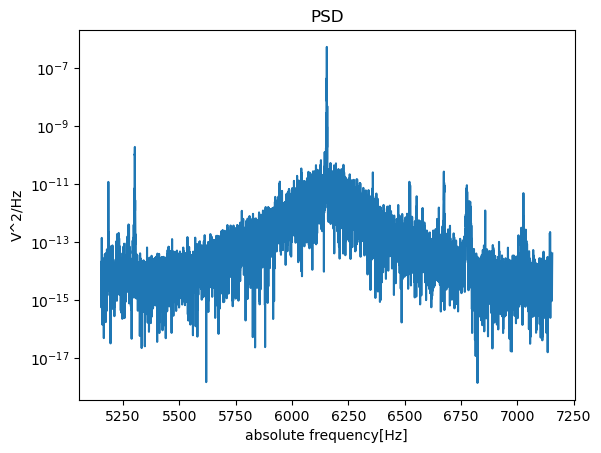

In [20]:
central_freq = result['dev1374']['demods']["0"]['sample.xiy.fft.abs.pwr'][0]["header"]['center'][0]
freq_span = freq_span
start_freq = central_freq - freq_span/2
end_freq   = central_freq + freq_span/2

time_taken = result['dev1374']['demods']["0"]["sample.xiy.fft.abs.pwr"][0]['timestamp'][0][-1] - result['dev1374']['demods']["0"]["sample.xiy.fft.abs.pwr"][0]['timestamp'][0][0] 
print(time_taken/10e3)

y_data_filter = np.array(result['dev1374']['demods']["0"]['sample.xiy.fft.abs.filter'][0]["value"][0])
y_data_linear_raw = np.array(result['dev1374']['demods']["0"]['sample.xiy.fft.abs.pwr'][0]["value"][0])
x_data = np.linspace(start_freq, end_freq, y_data_linear_raw.shape[0])
freq_res = x_data[1]-x_data[0]
fft_len = y_data_linear_raw.shape[0]

y_data_linear = y_data_linear_raw/y_data_filter
y_data_linear_PSD = y_data_linear*freq_res
print(y_data_linear.shape)

print(f"freq_res:{freq_res}Hz")



plt.yscale("log")
plt.plot(x_data,y_data_linear)
plt.xlabel("absolute frequency[Hz]")
plt.ylabel("V^2/Hz")
plt.title("PSD")